# Experiment 1 — Dataset inspection

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [27]:

df = pd.read_csv("/home/vitquay1708/Study_Space/NLP/lab4/imdb/IMDB Dataset.csv")
df.head(5)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


#### Số lượng sample và số lượng class

Total samples: 50000
Number of classes: 2
Classes: ['positive' 'negative']
           count  percentage
sentiment                   
positive   25000        50.0
negative   25000        50.0


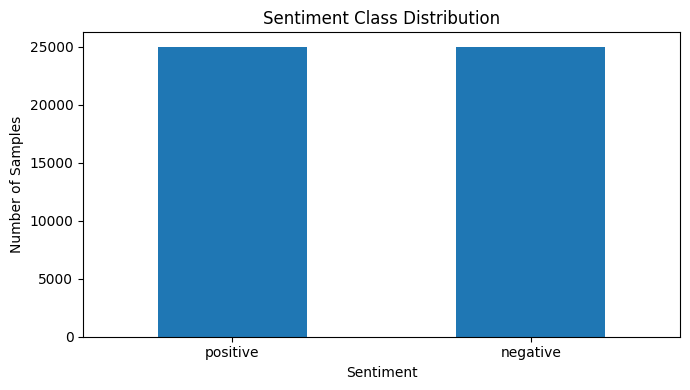

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: review, dtype: float64
Empty/whitespace-only reviews: 0


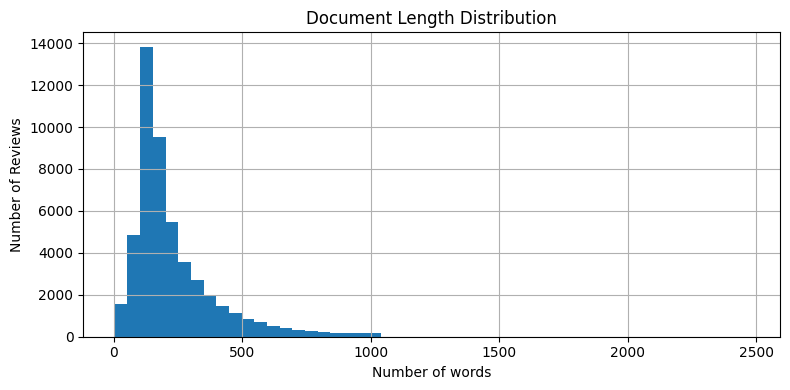

Rows belonging to duplicate review groups: 824
Duplicate occurrences (excluding first copies): 418

Examples of duplicate reviews:
review
Loved today's show!!! It was a variety and not solely cooking (which would have been great too). Very stimulating and captivating, always keeping the viewer peeking around the corner to see what was coming up next. She is as down to earth and as personable as you get, like one of us which made the show all the more enjoyable. Special guests, who are friends as well made for a nice surprise too. Loved the 'first' theme and that the audience was invited to play along too. I must admit I was shocked to see her come in under her time limits on a few things, but she did it and by golly I'll be writing those recipes down. Saving time in the kitchen means more time with family. Those who haven't tuned in yet, find out what channel and the time, I assure you that you won't be disappointed.                                                                      

In [28]:
print(f"Total samples: {len(df)}")
print(f"Number of classes: {df['sentiment'].nunique(dropna=True)}")
print(f"Classes: {df['sentiment'].dropna().unique()}")
class_counts = df["sentiment"].value_counts(dropna=False)
class_percent = df["sentiment"].value_counts(
    normalize=True, dropna=False
) * 100

distribution = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent
})
print(distribution)

df["sentiment"].value_counts().plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Exclude missing text before calculating length
valid_reviews = df["review"].dropna().astype(str)
doc_length = valid_reviews.str.split().str.len()

print(doc_length.describe())

print(f"Empty/whitespace-only reviews: "
      f"{df['review'].dropna().astype(str).str.strip().eq('').sum()}")

doc_length.hist(bins=50, figsize=(8, 4))
plt.title("Document Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

valid_text = df["review"].dropna().astype(str)

duplicate_mask = valid_text.duplicated(keep=False)
print(f"Rows belonging to duplicate review groups: "
      f"{duplicate_mask.sum()}")

print(f"Duplicate occurrences (excluding first copies): "
      f"{valid_text.duplicated().sum()}")

print("\nExamples of duplicate reviews:")
print(valid_text[duplicate_mask].value_counts().head(10))

missing_text = df["review"].isna().sum()
print(f"Missing reviews: {missing_text}")
print(f"Missing review percentage: "
      f"{df['review'].isna().mean() * 100:.2f}%")

missing_labels = df["sentiment"].isna().sum()
print(f"Missing labels: {missing_labels}")
print(f"Missing label percentage: "
      f"{df['sentiment'].isna().mean() * 100:.2f}%")


# Experiment 2: Baseline

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [30]:
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)
print(f"Số lượng mẫu sau khi xóa trùng lặp: {len(df)}")

Số lượng mẫu sau khi xóa trùng lặp: 49582


In [31]:
X = df["review"].astype(str)
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, train_size=0.8)


In [32]:
baseline = Pipeline([
  ("tfidf", TfidfVectorizer(
    lowercase=True,
    max_features=1000,
    ngram_range=(1, 2),
    sublinear_tf=True
  )),
  ("lr", LogisticRegression(max_iter=10000, random_state=42))
])

In [33]:
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.87      0.84      0.86      4939
    positive       0.85      0.87      0.86      4978

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



# Experiment 3: Representation comparison

In [34]:
from Word2VecVectorizer import Word2VecVectorizer

## Word2Vec + Logistic Regression

In [35]:
model2 = Pipeline([
  ("w2v", Word2VecVectorizer(vector_size=100,
                             window=5,
                             min_count=10,
                             epochs=10)),
  ("lr", LogisticRegression(max_iter=10000, random_state=42))
])



In [36]:
model2.fit(X_train, y_train)
y_pred2 = model2.predict(X_test)
print(classification_report(y_test, y_pred2))

              precision    recall  f1-score   support

    negative       0.86      0.85      0.85      4939
    positive       0.85      0.86      0.86      4978

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



## TF-IDF + Linear SVM

In [37]:
from sklearn.svm import LinearSVC

In [38]:
model3 = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=10000,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(C=1.0))
])



In [39]:
# Huấn luyện
model3.fit(X_train, y_train)

# Dự đoán
y_pred = model3.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.90      0.89      0.90      4939
    positive       0.89      0.90      0.90      4978

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

y_pred_tfidf_lr = baseline.predict(X_test)
y_pred_w2v_lr   = model2.predict(X_test)
y_pred_tfidf_svm = model3.predict(X_test)

def get_metrics(rep_name, clf_name, y_true, y_pred):
    return {
        "Representation": rep_name,
        "Classifier": clf_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred, average="macro"), 4),
        "Recall": round(recall_score(y_true, y_pred, average="macro"), 4),
        "F1": round(f1_score(y_true, y_pred, average="macro"), 4),
    }

# 3. Gom kết quả vào danh sách
comparison_data = [
    get_metrics("TF-IDF", "Logistic Regression", y_test, y_pred_tfidf_lr),
    get_metrics("Avg Word2Vec", "Logistic Regression", y_test, y_pred_w2v_lr),
    get_metrics("TF-IDF", "Linear SVM", y_test, y_pred_tfidf_svm),
]

# 4. Tạo DataFrame và in ra định dạng bảng
df_exp3 = pd.DataFrame(comparison_data)

print("Bảng so sánh hiệu năng các mô hình:")
display(df_exp3)

Bảng so sánh hiệu năng các mô hình:


,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression,0.8582,0.8585,0.8582,0.8582
1,Avg Word2Vec,Logistic Regression,0.8555,0.8556,0.8555,0.8555
2,TF-IDF,Linear SVM,0.8961,0.8962,0.8961,0.8961


# Experiment 4: Word order

In [41]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. Định nghĩa các cặp câu kiểm thử
sentences = {
    "S1 (Positive)": "this movie is good",
    "S2 (Negative)": "this movie is not good",
    "S3 (Positive - Đảo từ)": "not bad it is good",
    "S4 (Negative - Đảo từ)": "not good it is bad"
}

# Lấy bộ trích xuất vector Word2Vec từ pipeline model2 đã fit
w2v_transformer = model2.named_steps["w2v"]

# 2. Vector hóa các câu bằng Averaged Word2Vec
sentence_texts = list(sentences.values())
vectors = w2v_transformer.transform(sentence_texts)

# 3. Tính Cosine Similarity giữa các cặp câu
sim_s1_s2 = cosine_similarity([vectors[0]], [vectors[1]])[0][0]
sim_s3_s4 = cosine_similarity([vectors[2]], [vectors[3]])[0][0]

print("=== 1. ĐỘ TƯƠNG ĐỒNG COSINE (COSINE SIMILARITY) ===")
print(f"Cosine Similarity giữa S1 ('good') và S2 ('not good'): {sim_s1_s2:.4f}")
print(f"Cosine Similarity giữa S3 ('not bad, good') và S4 ('not good, bad'): {sim_s3_s4:.4f}")

# 4. Kiểm tra dự đoán của Model 2 (Avg Word2Vec + Logistic Regression)
preds_w2v = model2.predict(sentence_texts)
probs_w2v = model2.predict_proba(sentence_texts)
classes = model2.classes_ 

# Kiểm tra thêm với mô hình Baseline (TF-IDF có n-gram) để đối chiếu
preds_tfidf = baseline.predict(sentence_texts)
probs_tfidf = baseline.predict_proba(sentence_texts)

results = []
for i, (name, text) in enumerate(sentences.items()):
    pos_idx = list(classes).index("positive")
    neg_idx = list(classes).index("negative")
    
    results.append({
        "Sentence": name,
        "Text": text,
        "Avg W2V Predict": preds_w2v[i],
        "W2V P(Positive)": f"{probs_w2v[i][pos_idx] * 100:.1f}%",
        "W2V P(Negative)": f"{probs_w2v[i][neg_idx] * 100:.1f}%",
        "TF-IDF Predict": preds_tfidf[i],
        "TF-IDF P(Positive)": f"{probs_tfidf[i][pos_idx] * 100:.1f}%"
    })

df_exp4 = pd.DataFrame(results)
print("\n=== 2. KẾT QUẢ DỰ ĐOÁN CỦA CÁC MÔ HÌNH ===")
display(df_exp4)

=== 1. ĐỘ TƯƠNG ĐỒNG COSINE (COSINE SIMILARITY) ===
Cosine Similarity giữa S1 ('good') và S2 ('not good'): 0.9633
Cosine Similarity giữa S3 ('not bad, good') và S4 ('not good, bad'): 1.0000

=== 2. KẾT QUẢ DỰ ĐOÁN CỦA CÁC MÔ HÌNH ===


,Sentence,Text,Avg W2V Predict,W2V P(Positive),W2V P(Negative),TF-IDF Predict,TF-IDF P(Positive)
0,S1 (Positive),this movie is good,positive,81.5%,18.5%,positive,80.3%
1,S2 (Negative),this movie is not good,negative,11.7%,88.3%,negative,35.3%
2,S3 (Positive - Đảo từ),not bad it is good,negative,0.0%,100.0%,negative,26.0%
3,S4 (Negative - Đảo từ),not good it is bad,negative,0.0%,100.0%,negative,4.3%


# Experiment 5: n-grams  features

In [42]:
import time
from sklearn.metrics import f1_score
configs = [
    {
        "name": "Unigram",
        "ngram_range": (1, 1)
    },
    {
        "name": "Uni + Bigram",
        "ngram_range": (1, 2)
    }
]


In [43]:
results = []
for cfg in configs:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=cfg["ngram_range"],
            min_df=5,              
            sublinear_tf=True
        )),
        ("lr", LogisticRegression(max_iter=1000, random_state=42))
    ])
    
    # 2. Đo thời gian huấn luyện (Training time)
    start_time = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time
    
    # 3. Lấy kích thước từ vựng (Vocabulary size)
    vocab_size = len(pipe.named_steps["tfidf"].vocabulary_)
    
    # 4. Đánh giá F1-score trên tập test
    y_pred = pipe.predict(X_test)
    f1 = f1_score(y_test, y_pred, average="macro")
    
    # 5. Lưu kết quả
    results.append({
        "Features": cfg["name"],
        "Vocabulary": f"{vocab_size:,}",
        "F1 (Macro)": f"{f1:.4f}",
        "Training time (s)": f"{train_time:.2f}s"
    })

In [44]:
df_comparison = pd.DataFrame(results)
print("=== KẾT QUẢ SO SÁNH EXPERIMENT 5 ===")
display(df_comparison)

=== KẾT QUẢ SO SÁNH EXPERIMENT 5 ===


,Features,Vocabulary,F1 (Macro),Training time (s)
0,Unigram,"33,549",0.8955,15.51s
1,Uni + Bigram,"224,227",0.9069,37.03s


# Confusion matrix cho 3 mô hình

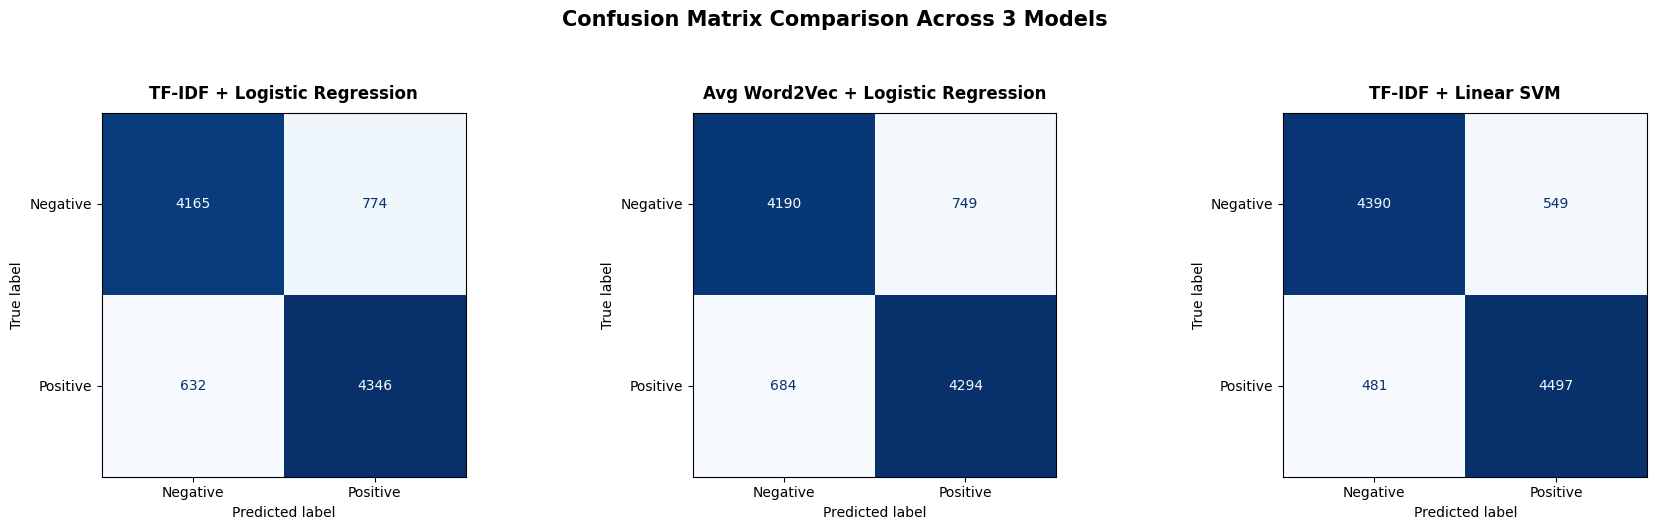

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_to_plot = [
    ("TF-IDF + Logistic Regression", y_pred_tfidf_lr),
    ("Avg Word2Vec + Logistic Regression", y_pred_w2v_lr),
    ("TF-IDF + Linear SVM", y_pred_tfidf_svm)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

labels = ["negative", "positive"]

for ax, (name, y_pred) in zip(axes, models_to_plot):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, 
        display_labels=["Negative", "Positive"]
    )
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    
    ax.set_title(name, fontsize=12, fontweight="bold", pad=10)
    ax.grid(False)

plt.suptitle("Confusion Matrix Comparison Across 3 Models", fontsize=15, y=1.05, fontweight="bold")
plt.tight_layout()
fig.savefig(
    "confusion_matrix.png",      # Tên file (hoặc đường dẫn: "/duong/dan/anh.png")
    dpi=300,                     # Độ phân giải cao (sắc nét, chuẩn chèn báo cáo/slide)
    bbox_inches="tight"          # Cắt bỏ khoảng viền trắng thừa, không bị mất tiêu đề
)

plt.show()

# Inspect model weights

=== BẢNG TOP FEATURES VÀ TRỌNG SỐ TƯƠNG ỨNG ===


,Top Positive Feature,Pos Weight,Top Negative Feature,Neg Weight
0,excellent,7.7282,worst,-8.4852
1,great,7.1857,bad,-8.3688
2,perfect,5.8706,awful,-8.3431
3,amazing,5.7590,waste,-8.0053
4,wonderful,5.4254,boring,-7.6966
5,brilliant,4.9527,terrible,-7.2306
6,loved,4.7572,poor,-6.6487
7,today,4.4583,the worst,-6.3194
8,enjoyed,4.0046,nothing,-5.3013
9,highly,3.9591,worse,-5.1658


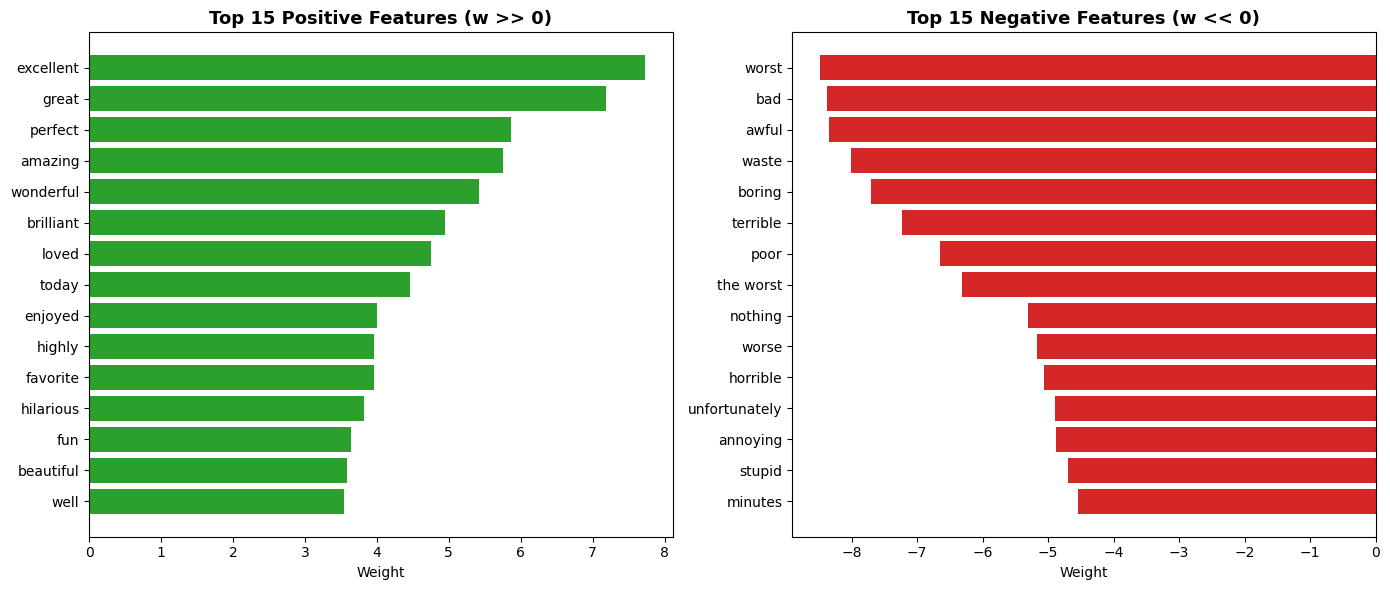

In [46]:
tfidf_step = baseline.named_steps["tfidf"]
lr_step = baseline.named_steps["lr"]
feature_names = tfidf_step.get_feature_names_out()
weights = lr_step.coef_[0]  
top_k = 15

top_pos_idx = np.argsort(weights)[::-1][:top_k]

top_neg_idx = np.argsort(weights)[:top_k]

df_top_features = pd.DataFrame({
    "Top Positive Feature": feature_names[top_pos_idx],
    "Pos Weight": np.round(weights[top_pos_idx], 4),
    "Top Negative Feature": feature_names[top_neg_idx],
    "Neg Weight": np.round(weights[top_neg_idx], 4)
})
print("=== BẢNG TOP FEATURES VÀ TRỌNG SỐ TƯƠNG ỨNG ===")
display(df_top_features)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.barh(feature_names[top_pos_idx][::-1], weights[top_pos_idx][::-1], color="#2ca02c")
ax1.set_title(f"Top {top_k} Positive Features (w >> 0)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Weight")

ax2.barh(feature_names[top_neg_idx][::-1], weights[top_neg_idx][::-1], color="#d62728")
ax2.set_title(f"Top {top_k} Negative Features (w << 0)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Weight")
plt.tight_layout()
plt.show()

# Application

In [47]:
test_cases = [
    ("The movie was absolutely amazing and captivating!", "positive"),
    ("I loved the story and the brilliant acting.", "positive"),
    ("An excellent film with beautiful cinematography.", "positive"),
    ("The characters were great and the ending was satisfying.", "positive"),
    ("This is one of the best movies I have ever watched.", "positive"),
    ("The movie was boring and terribly disappointing.", "negative"),
    ("I hated the story and the acting was awful.", "negative"),
    ("A terrible film with a weak and predictable plot.", "negative"),
    ("The characters were dull and the ending was disappointing.", "negative"),
    ("This is one of the worst movies I have ever watched.", "negative"),
]

df_app = pd.DataFrame(test_cases, columns=["review", "sentiment"])

df_app = df_app.sample(frac=1, random_state=42).reset_index(drop=True)

print(df_app)

                                              review sentiment
0  The characters were dull and the ending was di...  negative
1        I loved the story and the brilliant acting.  positive
2   The movie was boring and terribly disappointing.  negative
3  The movie was absolutely amazing and captivating!  positive
4  A terrible film with a weak and predictable plot.  negative
5   An excellent film with beautiful cinematography.  positive
6  This is one of the worst movies I have ever wa...  negative
7  This is one of the best movies I have ever wat...  positive
8  The characters were great and the ending was s...  positive
9        I hated the story and the acting was awful.  negative


In [48]:
models = {
    "TF-IDF + Logistic Regression": baseline,
    "Avg Word2Vec + Logistic Regression": model2,
    "TF-IDF + Linear SVM": model3
}

X_app = df_app["review"]
y_app = df_app["sentiment"]

for name, model in models.items():
    y_pred = model.predict(X_app)
    df_result = pd.DataFrame({
        "review": X_app,
        "ground_truth": y_app,
        "predicted": y_pred
    })
    
    acc = accuracy_score(y_app, y_pred)
    
    print(f"\n==================================================")
    print(f" MÔ HÌNH: {name} (Độ chính xác: {acc * 100:.1f}%)")
    print(f"==================================================")
    display(df_result)


 MÔ HÌNH: TF-IDF + Logistic Regression (Độ chính xác: 90.0%)


,review,ground_truth,predicted
0,The characters were dull and the ending was di...,negative,positive
1,I loved the story and the brilliant acting.,positive,positive
2,The movie was boring and terribly disappointing.,negative,negative
3,The movie was absolutely amazing and captivating!,positive,positive
4,A terrible film with a weak and predictable plot.,negative,negative
5,An excellent film with beautiful cinematography.,positive,positive
6,This is one of the worst movies I have ever wa...,negative,negative
7,This is one of the best movies I have ever wat...,positive,positive
8,The characters were great and the ending was s...,positive,positive
9,I hated the story and the acting was awful.,negative,negative



 MÔ HÌNH: Avg Word2Vec + Logistic Regression (Độ chính xác: 100.0%)


,review,ground_truth,predicted
0,The characters were dull and the ending was di...,negative,negative
1,I loved the story and the brilliant acting.,positive,positive
2,The movie was boring and terribly disappointing.,negative,negative
3,The movie was absolutely amazing and captivating!,positive,positive
4,A terrible film with a weak and predictable plot.,negative,negative
5,An excellent film with beautiful cinematography.,positive,positive
6,This is one of the worst movies I have ever wa...,negative,negative
7,This is one of the best movies I have ever wat...,positive,positive
8,The characters were great and the ending was s...,positive,positive
9,I hated the story and the acting was awful.,negative,negative



 MÔ HÌNH: TF-IDF + Linear SVM (Độ chính xác: 100.0%)


,review,ground_truth,predicted
0,The characters were dull and the ending was di...,negative,negative
1,I loved the story and the brilliant acting.,positive,positive
2,The movie was boring and terribly disappointing.,negative,negative
3,The movie was absolutely amazing and captivating!,positive,positive
4,A terrible film with a weak and predictable plot.,negative,negative
5,An excellent film with beautiful cinematography.,positive,positive
6,This is one of the worst movies I have ever wa...,negative,negative
7,This is one of the best movies I have ever wat...,positive,positive
8,The characters were great and the ending was s...,positive,positive
9,I hated the story and the acting was awful.,negative,negative


In [49]:
df_comparison_app = pd.DataFrame({
    "review": df_app["review"],
    "ground_truth": df_app["sentiment"],
    "TF-IDF + LR": baseline.predict(X_app),
    "Word2Vec + LR": model2.predict(X_app),
    "TF-IDF + SVM": model3.predict(X_app),
})

print("\n=== BẢNG TỔNG HỢP SO SÁNH DỰ ĐOÁN 3 MÔ HÌNH TRÊN DF_APP ===")
display(df_comparison_app)


=== BẢNG TỔNG HỢP SO SÁNH DỰ ĐOÁN 3 MÔ HÌNH TRÊN DF_APP ===


,review,ground_truth,TF-IDF + LR,Word2Vec + LR,TF-IDF + SVM
0,The characters were dull and the ending was di...,negative,positive,negative,negative
1,I loved the story and the brilliant acting.,positive,positive,positive,positive
2,The movie was boring and terribly disappointing.,negative,negative,negative,negative
3,The movie was absolutely amazing and captivating!,positive,positive,positive,positive
4,A terrible film with a weak and predictable plot.,negative,negative,negative,negative
5,An excellent film with beautiful cinematography.,positive,positive,positive,positive
6,This is one of the worst movies I have ever wa...,negative,negative,negative,negative
7,This is one of the best movies I have ever wat...,positive,positive,positive,positive
8,The characters were great and the ending was s...,positive,positive,positive,positive
9,I hated the story and the acting was awful.,negative,negative,negative,negative
